## Packages

In [66]:
import numpy as np
import pandas as pd
import scipy
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels.graphics.tsaplots as sgt
import statsmodels.tsa.stattools as sts
# from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima.arima import auto_arima
from arch import arch_model
import yfinance
import warnings
warnings.filterwarnings("ignore")
sns.set()

## Loading the data

In [67]:
raw_data = yfinance.download (tickers = "^GSPC ^FTSE ^N225 ^GDAXI", start = "1994-01-07", end = "2018-01-29", 
                              interval = "1d", group_by = 'ticker', auto_adjust = True, threads = True)

[*********************100%***********************]  4 of 4 completed


In [68]:
df_comp = raw_data.copy()

df_comp['spx'] = df_comp['^GSPC']['Close']
df_comp['dax'] = df_comp['^GDAXI']['Close']
df_comp['ftse'] = df_comp['^FTSE']['Close']
df_comp['nikkei'] = df_comp['^N225']['Close']

In [69]:
df_comp = df_comp.iloc[1:]
del df_comp['^N225']
del df_comp['^GSPC']
del df_comp['^GDAXI']
del df_comp['^FTSE']
df_comp=df_comp.asfreq('b')
df_comp=df_comp.ffill()

## Creating Returns

In [70]:
df_comp['ret_spx'] = df_comp.spx.pct_change(1).mul(100)
df_comp['ret_ftse'] = df_comp.ftse.pct_change(1).mul(100)
df_comp['ret_dax'] = df_comp.dax.pct_change(1).mul(100)
df_comp['ret_nikkei'] = df_comp.nikkei.pct_change(1).mul(100)

In [71]:
df_comp['norm_ret_spx'] = df_comp.ret_spx.div(df_comp.ret_spx[1])*100
df_comp['norm_ret_ftse'] = df_comp.ret_ftse.div(df_comp.ret_ftse[1])*100
df_comp['norm_ret_dax'] = df_comp.ret_dax.div(df_comp.ret_dax[1])*100
df_comp['norm_ret_nikkei'] = df_comp.ret_nikkei.div(df_comp.ret_nikkei[1])*100

## Splitting the Data

In [72]:
size = int(len(df_comp)*0.8)
# df, df_test = df_comp.iloc[:size], df_comp.iloc[size:]
df = df_comp.iloc[:size].copy()
df_test = df_comp.iloc[size:].copy()

## Fitting a Model

In [73]:
model_ar = ARIMA(df.ftse, order = (1,0,0))
results_ar = model_ar.fit()

## Simple Forecastingm

In [74]:
df.tail()

Ticker,spx,dax,ftse,nikkei,ret_spx,ret_ftse,ret_dax,ret_nikkei,norm_ret_spx,norm_ret_ftse,norm_ret_dax,norm_ret_nikkei
Price,,,,,,,,,,,,
Date,,,,,,,,,,,,
2013-04-01,1562.170044,7795.310059,6411.700195,12135.019531,-0.447358,0.000000,0.000000,-2.120443,186.507731,-0.000000,0.000000,-935.368371
2013-04-02,1570.250000,7943.870117,6490.700195,12003.429688,0.517226,1.232122,1.905762,-1.084381,-215.636502,-158.180337,1367.802234,-478.341386
2013-04-03,1553.689941,7874.750000,6420.299805,12362.200195,-1.054613,-1.084635,-0.870106,2.988900,439.677916,139.245809,-624.492133,1318.461488
2013-04-04,1559.979980,7817.390137,6344.100098,12634.540039,0.404845,-1.186856,-0.728402,2.203005,-168.783728,152.368996,-522.788437,971.787879
2013-04-05,1553.280029,7658.750000,6249.799805,12833.639648,-0.429490,-1.486425,-2.029324,1.575836,179.058193,190.827793,-1456.484709,695.131611


In [75]:
start_date = "2014-07-15"
end_date = "2015-01-01"

In [76]:
end_date = "2019-10-23"
df_pred = results_ar.predict(start = start_date, end = end_date)

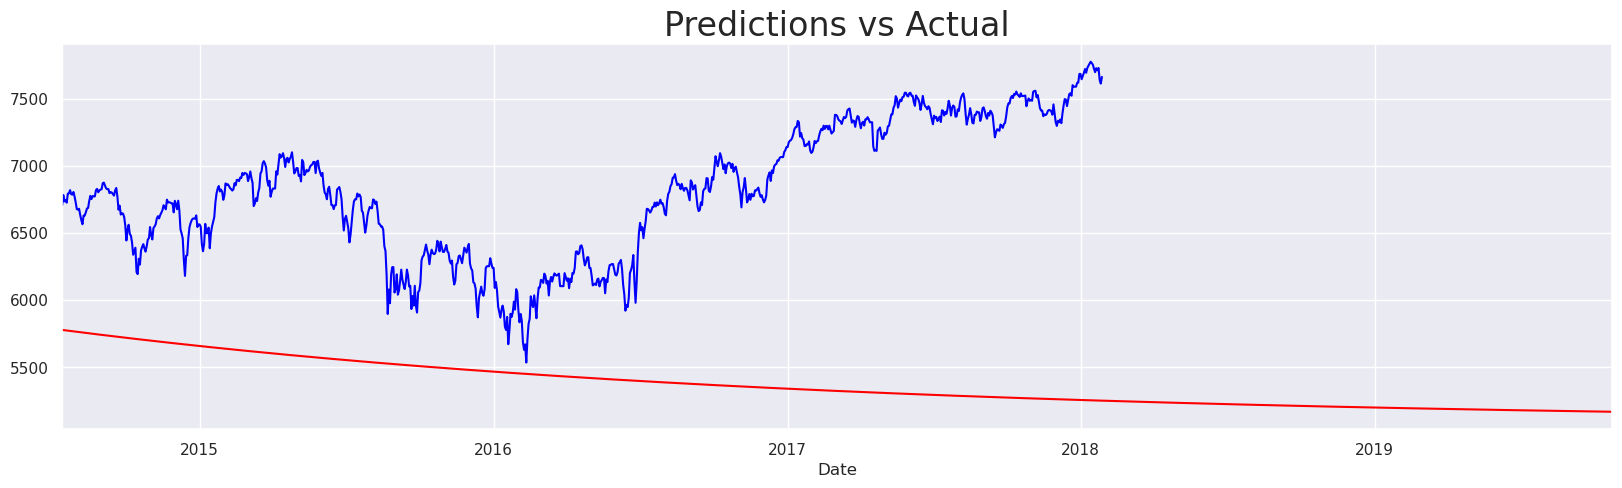

In [77]:
df_pred[start_date:end_date].plot(figsize = (20,5), color = "red")
df_test.ftse[start_date:end_date].plot(color = "blue")
plt.title("Predictions vs Actual", size = 24)
plt.show()

### Using Returns Instead

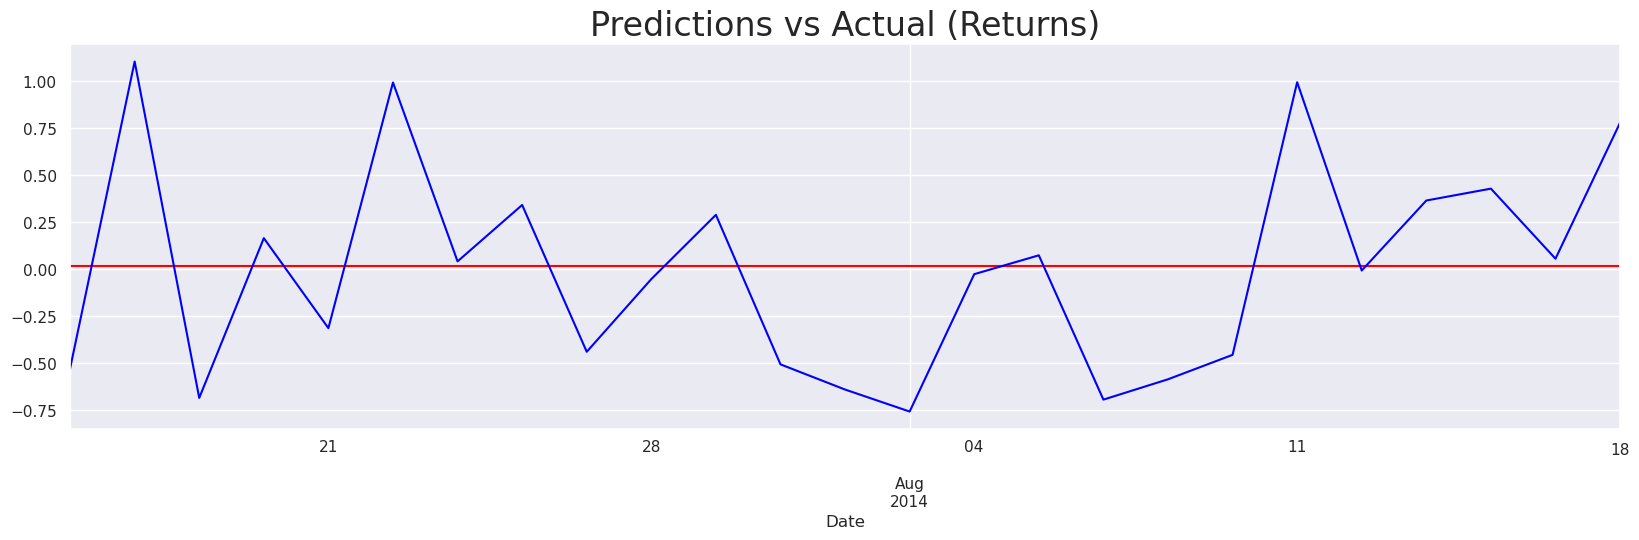

In [78]:
end_date = "2014-08-18"

model_ret_ar = ARIMA(df.ret_ftse[1:], order = (5,0,0))
results_ret_ar = model_ret_ar.fit()

df_pred_ar = results_ret_ar.predict(start = start_date, end = end_date) 

df_pred_ar[start_date:end_date].plot(figsize = (20,5), color = "red")
df_test.ret_ftse[start_date:end_date].plot(color = "blue")
plt.title("Predictions vs Actual (Returns)", size = 24)
plt.show()

In [79]:
results_ret_ar.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:               ret_ftse   No. Observations:                 5019
Model:                 ARIMA(5, 0, 0)   Log Likelihood               -7891.459
Date:                Sat, 28 Nov 2026   AIC                          15796.918
Time:                        20:52:27   BIC                          15842.565
Sample:                    01-11-1994   HQIC                         15812.913
                         - 04-05-2013                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0189      0.015      1.277      0.202      -0.010       0.048
ar.L1         -0.0218      0.009     -2.398      0.016      -0.040      -0.004
ar.L2         -0.0545      0.008     -6.835      0.000      -0.070      -0.039
ar.L3         -0.0833      0.008    -10.422      0.000      -0.099      -0.068
ar.L4          0.0449      0.008      5.424      0.000       0.029       0.061
ar.L5         -0.0594      0.008     -7.436      0.000      -0.075      -0.044
sigma2         1.3590      0.015     92.498      0.000       1.330       1.388
===================================================================================
Ljung-Box (L1) (Q):                   0.04   Jarque-Bera (JB):              6389.23
Prob(Q):                              0.85   Prob(JB):                         0.00
Heteroskedasticity (H):               2.00   Skew:                            -0.17
Prob(H) (two-sided):                  0.00   Kurtosis:                         8.52
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

### MA

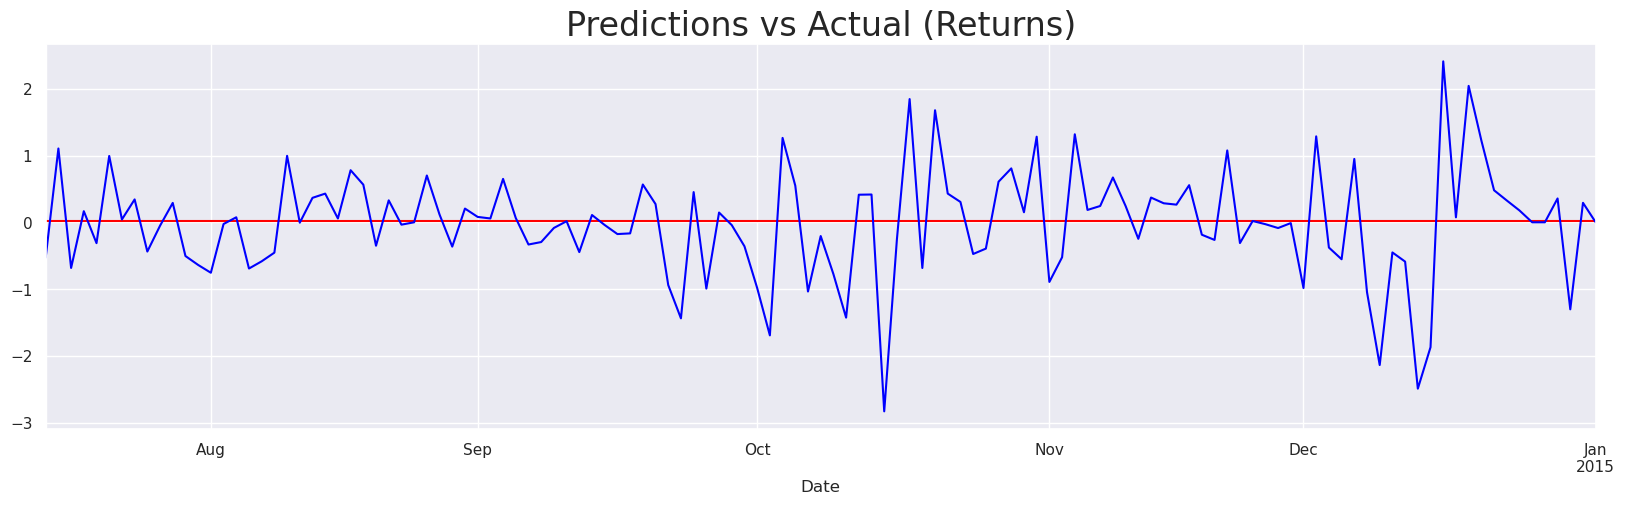

In [80]:
end_date = "2015-01-01"

model_ret_ma = ARIMA(df.ret_ftse[1:], order=(0,0,1))
results_ret_ma = model_ret_ma.fit()

df_pred_ma = results_ret_ma.predict(start = start_date, end = end_date) 

df_pred_ma[start_date:end_date].plot(figsize = (20,5), color = "red")   
df_test.ret_ftse[start_date:end_date].plot(color = "blue")
plt.title("Predictions vs Actual (Returns)", size = 24)
plt.show()

In [81]:
df_pred_ma.head()

2014-07-15    0.018805
2014-07-16    0.018805
2014-07-17    0.018805
2014-07-18    0.018805
2014-07-21    0.018805
Freq: B, Name: predicted_mean, dtype: float64

### ARMA

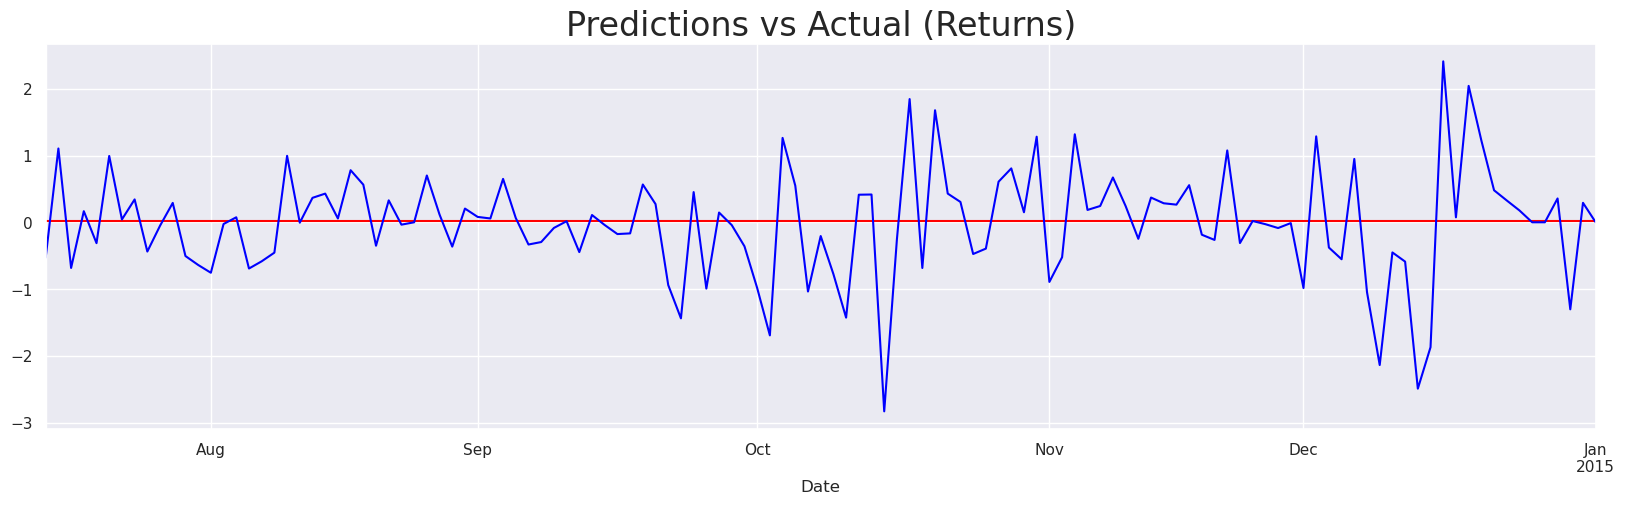

In [82]:
model_ret_arma = ARIMA(df.ret_ftse[1:], order=(1,0,1))
results_ret_arma = model_ret_arma.fit()

df_pred_arma = results_ret_arma.predict(start = start_date, end = end_date)

df_pred_arma[start_date:end_date].plot(figsize = (20,5), color = "red")   
df_test.ret_ftse[start_date:end_date].plot(color = "blue")
plt.title("Predictions vs Actual (Returns)", size = 24)
plt.show()

In [83]:
df_pred_arma.head()

2014-07-15    0.018935
2014-07-16    0.018935
2014-07-17    0.018935
2014-07-18    0.018935
2014-07-21    0.018935
Freq: B, Name: predicted_mean, dtype: float64

In [84]:
df_pred_arma.tail()

2014-12-26    0.018935
2014-12-29    0.018935
2014-12-30    0.018935
2014-12-31    0.018935
2015-01-01    0.018935
Freq: B, Name: predicted_mean, dtype: float64

### ARMAX

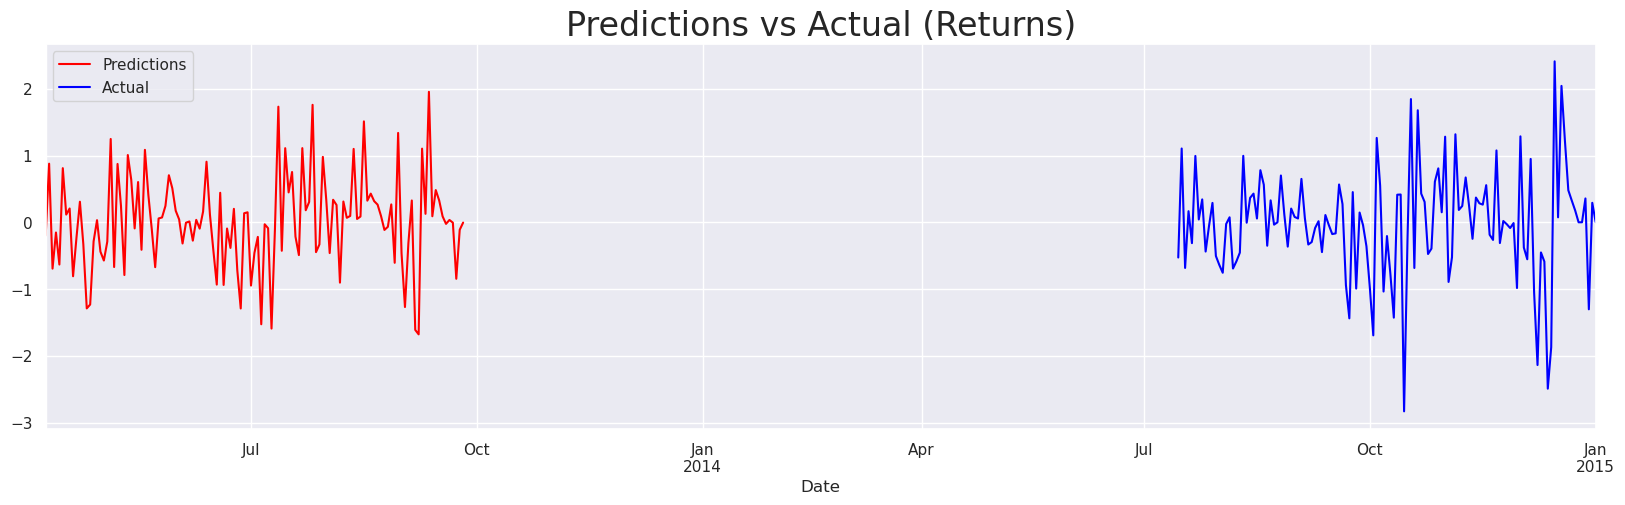

In [85]:
# Liczba obserwacji w zbiorze testowym
n_forecast = len(df_test[start_date:end_date])

# Prognozowanie
df_pred_armax = results_ret_armax.get_forecast(
    steps=n_forecast,
    exog=df_test[["ret_spx", "ret_dax", "ret_nikkei"]].loc[start_date:end_date]
).predicted_mean

# Wykres
df_pred_armax.plot(figsize=(20, 5), color="red")
df_test.ret_ftse.loc[start_date:end_date].plot(color="blue")

plt.title("Predictions vs Actual (Returns)", size=24)
plt.legend(["Predictions", "Actual"])
plt.show()

### SARMA

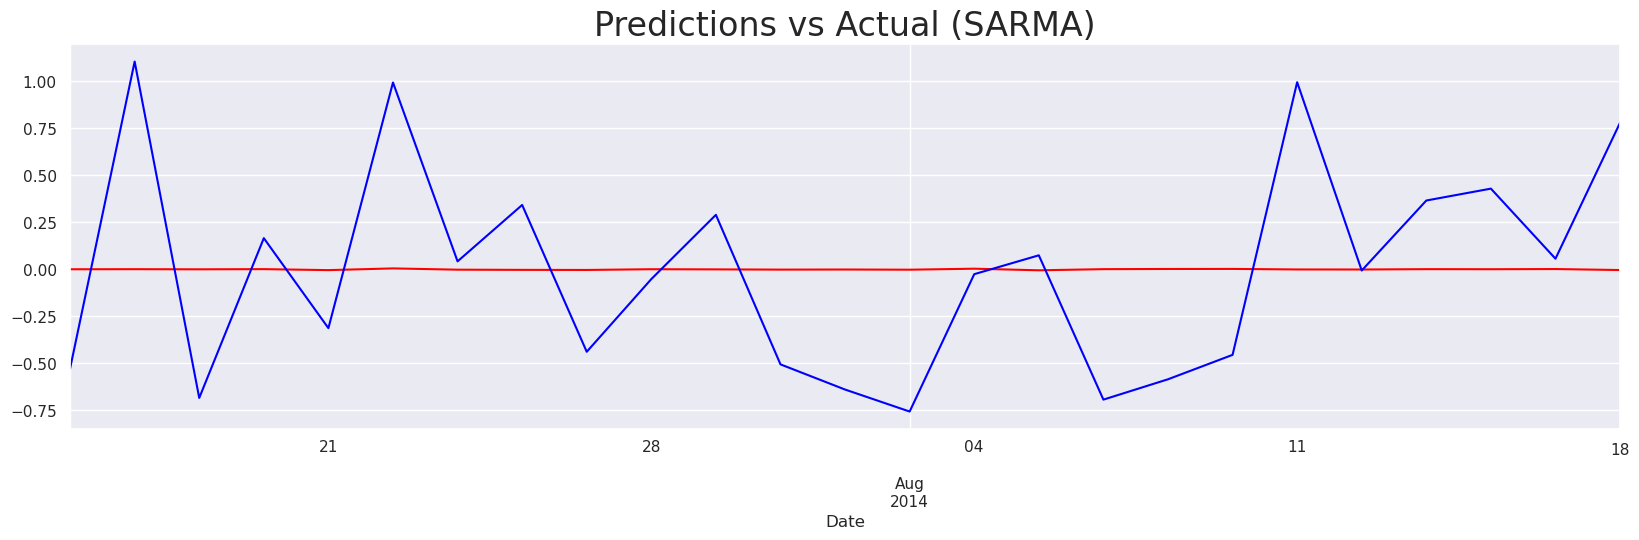

In [86]:
end_date = "2014-08-18"
model_ret_sarma = SARIMAX(df.ret_ftse[1:], order = (3,0,4), seasonal_order = (3,0,2,5))
results_ret_sarma = model_ret_sarma.fit()

df_pred_sarma = results_ret_sarma.predict(start = start_date, end = end_date)

df_pred_sarma[start_date:end_date].plot(figsize = (20,5), color = "red")
df_test.ret_ftse[start_date:end_date].plot(color = "blue")
plt.title("Predictions vs Actual (SARMA)", size = 24)
plt.show()

### SARIMAX

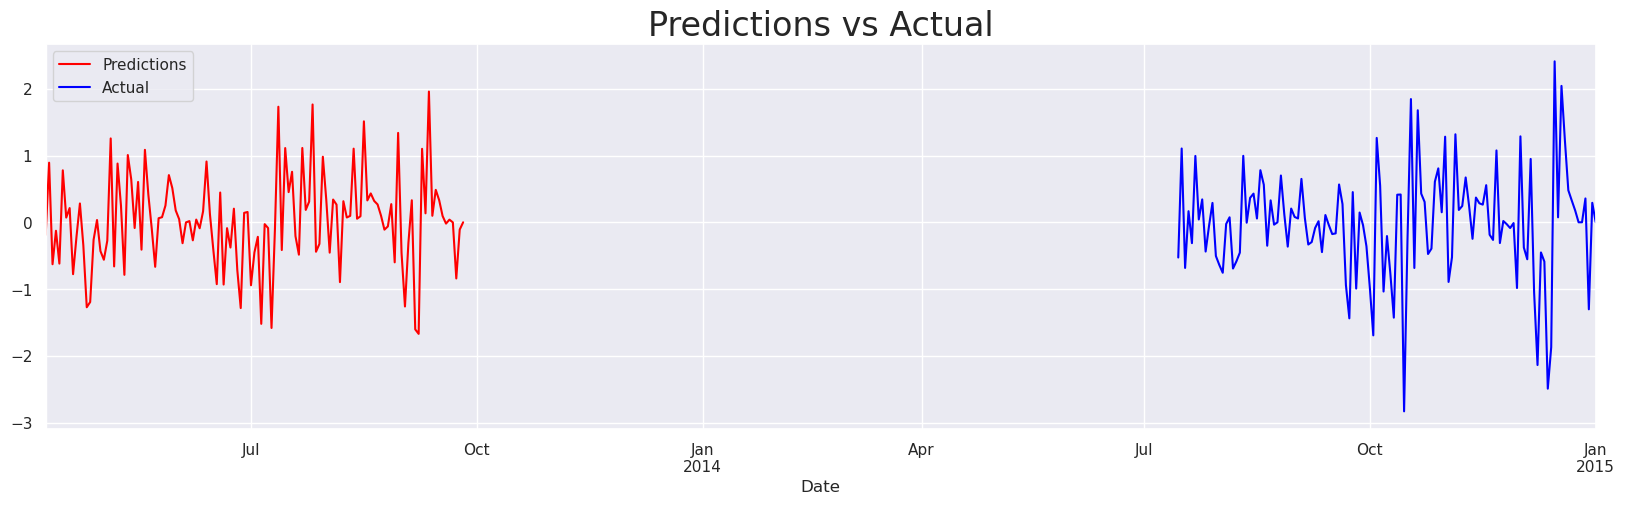

In [87]:
end_date = "2015-01-01"

model_ret_sarimax = SARIMAX(
    df.ret_ftse[1:],
    exog=df[["ret_spx", "ret_dax", "ret_nikkei"]][1:],
    order=(3, 0, 4),
    seasonal_order=(3, 0, 2, 5)
)

results_ret_sarimax = model_ret_sarimax.fit()

# Przygotowanie zmiennych egzogenicznych
exog_test = df_test.loc[
    start_date:end_date,
    ["ret_spx", "ret_dax", "ret_nikkei"]
]

# Prognozowanie
df_pred_sarimax = results_ret_sarimax.get_forecast(
    steps=len(exog_test),
    exog=exog_test
).predicted_mean

# Wykres prognoz i wartości rzeczywistych
df_pred_sarimax.plot(figsize=(20, 5), color="red")
df_test.ret_ftse.loc[start_date:end_date].plot(color="blue")

plt.title("Predictions vs Actual", size=24)
plt.legend(["Predictions", "Actual"])
plt.show()

### Auto ARIMA

In [88]:
model_auto = auto_arima(df.ret_ftse[1:], exogenous = df[['ret_spx', 'ret_dax', 'ret_nikkei']][1:],
                       m = 5, max_p = 5, max_q = 5, max_P = 5, max_Q = 5)

In [89]:
df_auto_pred = pd.DataFrame(model_auto.predict(n_periods = len(df_test[start_date:end_date]),
                            exogenous = df_test[['ret_spx', 'ret_dax', 'ret_nikkei']][start_date:end_date]),
                            index = df_test[start_date:end_date].index)

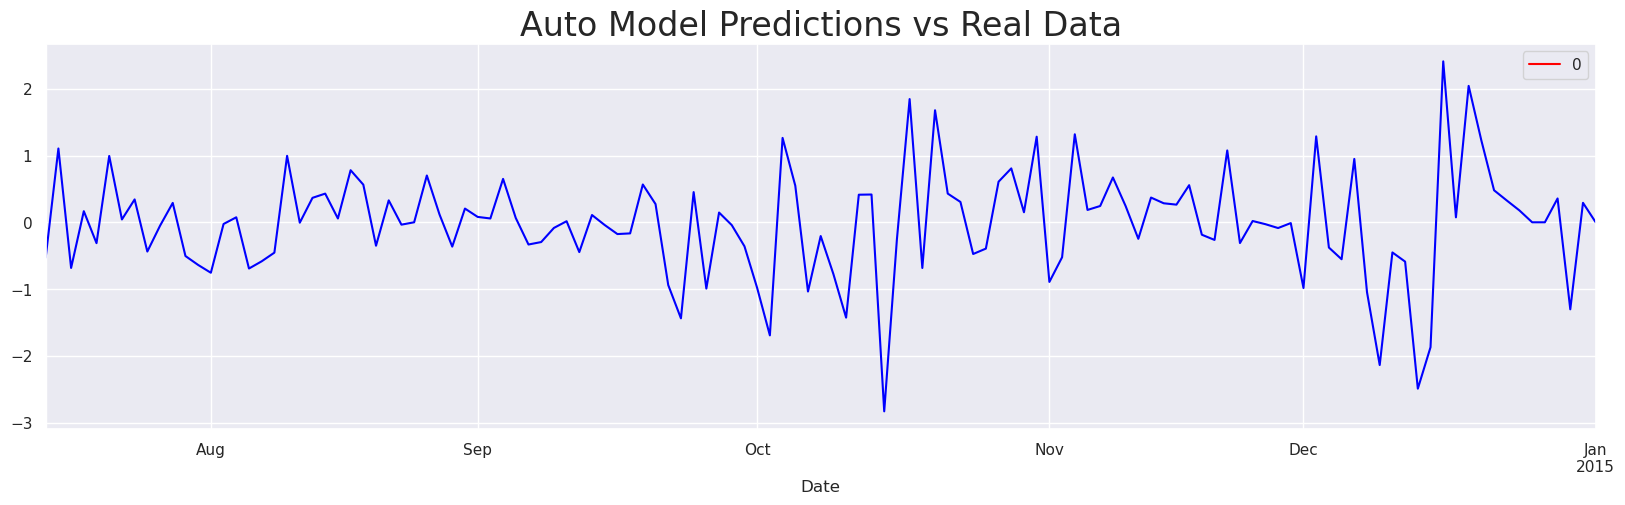

In [90]:
df_auto_pred.plot(figsize = (20,5), color = "red")
df_test.ret_ftse[start_date:end_date].plot(color = "blue")
plt.title("Auto Model Predictions vs Real Data", size = 24)
plt.show()

### Comparing All the Models (Returns)

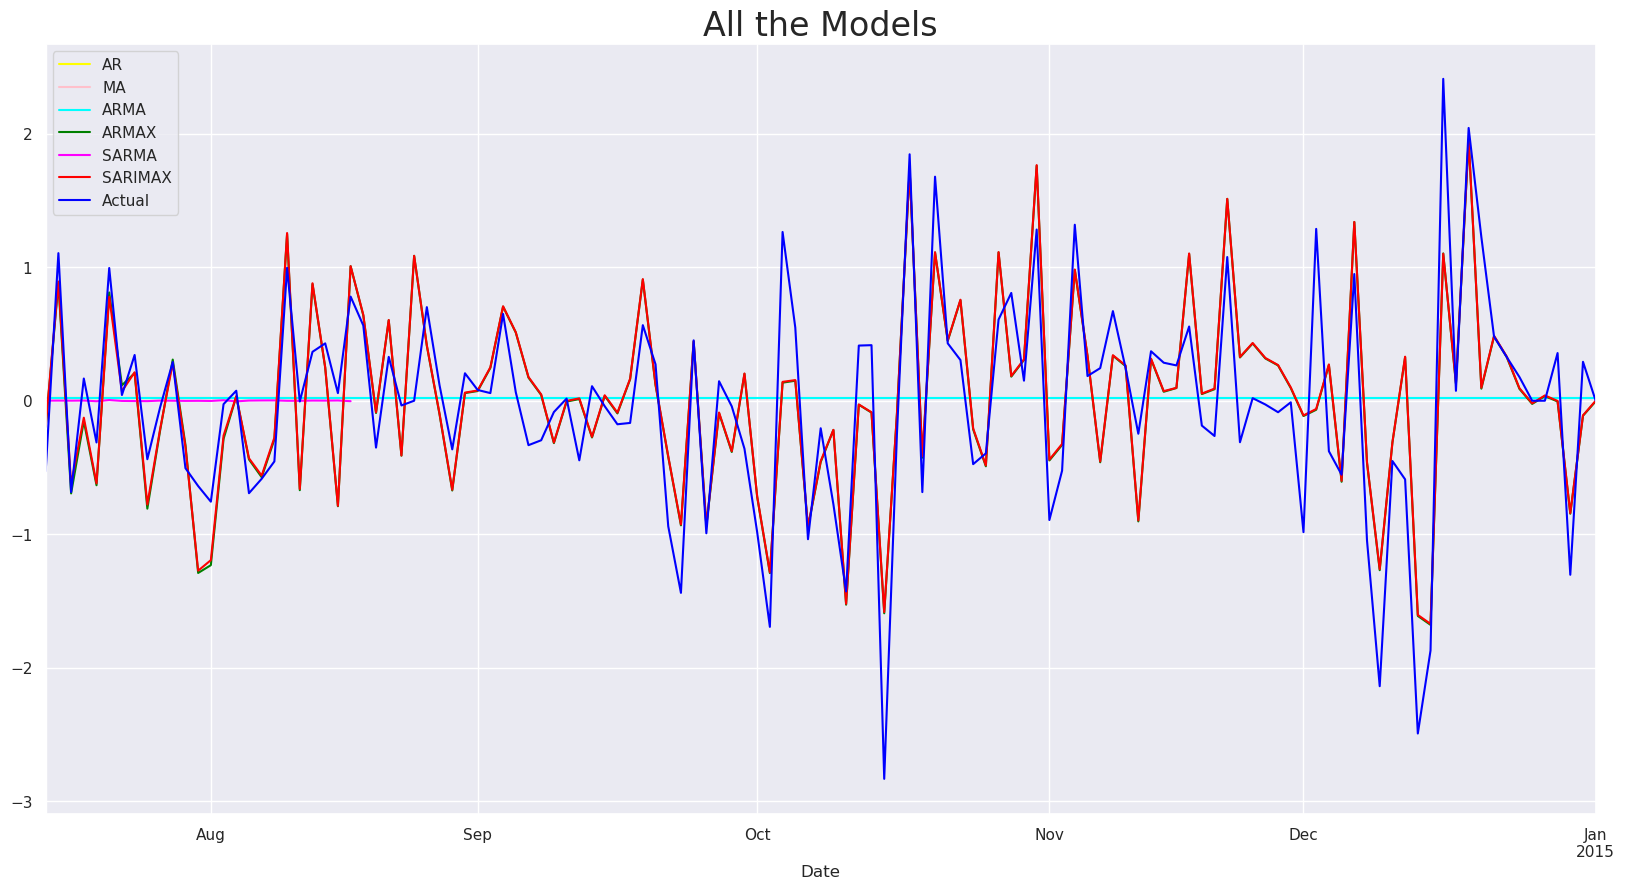

In [91]:
end_date = "2015-01-01"

# Dopasowanie indeksów prognoz do danych testowych
test_index = df_test.loc[start_date:end_date].index

df_pred_armax.index = test_index
df_pred_sarimax.index = test_index

# Wykres wszystkich modeli
df_pred_ar[start_date:end_date].plot(figsize=(20, 10), color="yellow")
df_pred_ma[start_date:end_date].plot(color="pink")
df_pred_arma[start_date:end_date].plot(color="cyan")
df_pred_armax.plot(color="green")
df_pred_sarma[start_date:end_date].plot(color="magenta")
df_pred_sarimax.plot(color="red")

df_test.ret_ftse[start_date:end_date].plot(color="blue")

plt.legend(['AR', 'MA', 'ARMA', 'ARMAX', 'SARMA', 'SARIMAX', 'Actual'])
plt.title("All the Models", size=24)
plt.show()

### Forecasting Volatility

In [92]:
mod_garch = arch_model(df_comp.ret_ftse[1:], vol = "GARCH", p = 1, q = 1, mean = "constant", dist = "Normal")
res_garch = mod_garch.fit(last_obs = start_date, update_freq = 10)

Iteration:     10,   Func. Count:     65,   Neg. LLF: 7309.738663280079
Optimization terminated successfully    (Exit mode 0)
            Current function value: 7309.738653886689
            Iterations: 12
            Function evaluations: 74
            Gradient evaluations: 12


In [93]:
pred_garch = res_garch.forecast(horizon = 1, align = 'target')

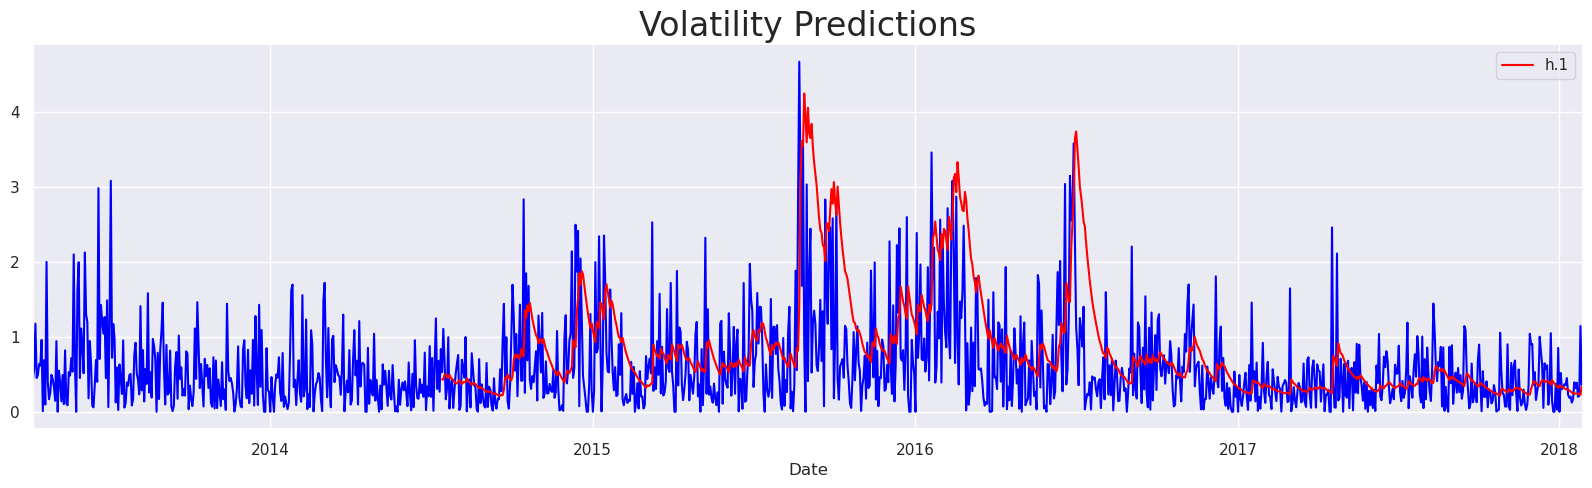

In [94]:
pred_garch.residual_variance[start_date:].plot(figsize = (20,5), color = "red", zorder = 2)
df_test.ret_ftse.abs().plot(color = "blue", zorder = 1)
plt.title("Volatility Predictions", size = 24)
plt.show()

In [95]:
pred_garch = res_garch.forecast(horizon = 100, align = 'target')
pred_garch.residual_variance[-1:]

,h.001,h.002,h.003,h.004,h.005,h.006,h.007,h.008,h.009,h.010,...,h.091,h.092,h.093,h.094,h.095,h.096,h.097,h.098,h.099,h.100
Date,,,,,,,,,,,,,,,,,,,,,
2018-01-26,0.325666,0.339335,0.24341,0.259997,0.274505,0.284425,0.293391,0.29712,0.312694,0.330342,...,0.874867,0.891624,0.910146,0.927307,0.938552,0.904733,0.863216,0.872782,0.885312,0.892351


### Multvariate Regression Model

In [96]:
from statsmodels.tsa.api import VAR

In [97]:
df_ret = df[['ret_spx', 'ret_dax', 'ret_ftse', 'ret_nikkei']][1:]

In [98]:
model_var_ret = VAR(df_ret)
model_var_ret.select_order(20)
results_var_ret = model_var_ret.fit(ic = 'aic')

In [99]:
results_var_ret.summary()

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sat, 28, Nov, 2026
Time:                     20:55:46
--------------------------------------------------------------------
No. of Equations:         4.00000    BIC:                   0.449050
Nobs:                     5014.00    HQIC:                  0.378098
Log likelihood:          -29226.2    FPE:                    1.40470
AIC:                     0.339820    Det(Omega_mle):         1.38141
--------------------------------------------------------------------
Results for equation ret_spx
                   coefficient       std. error           t-stat            prob
--------------------------------------------------------------------------------
const                 0.035802         0.017040            2.101           0.036
L1.ret_spx           -0.112462         0.018140           -6.200           0.000
L1.ret_dax            0.064253         0.019679           

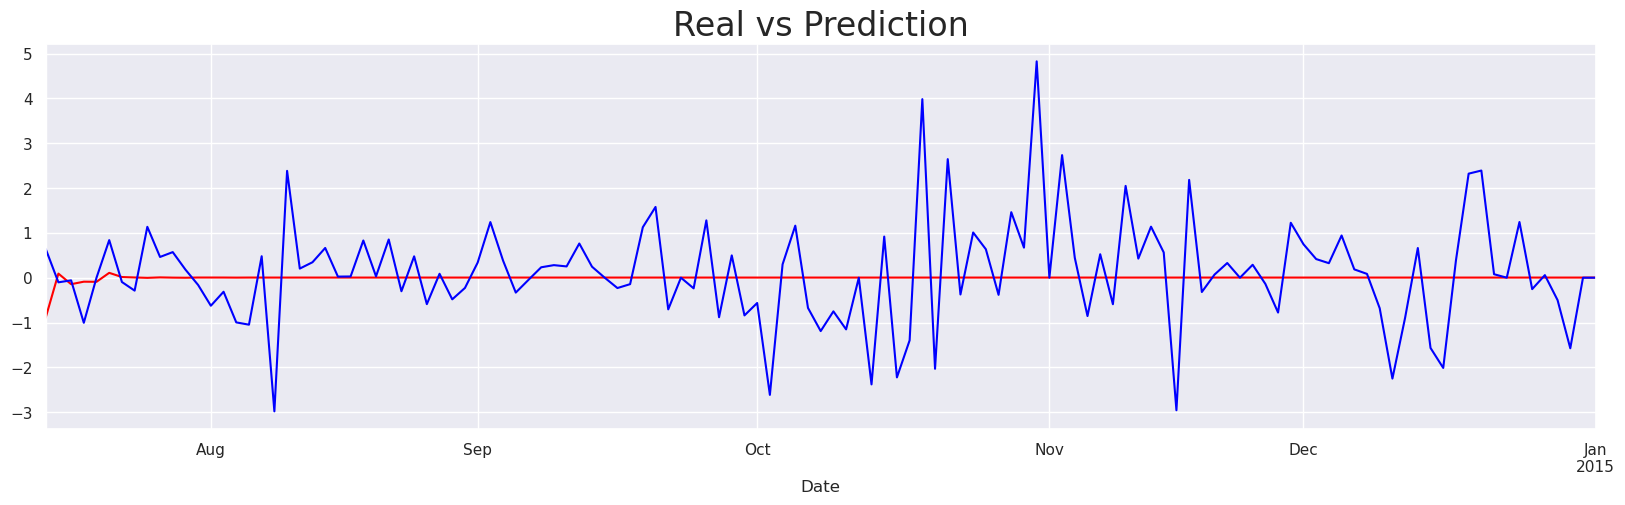

In [100]:
lag_order_ret = results_var_ret.k_ar
var_pred_ret = results_var_ret.forecast(df_ret.values[-lag_order_ret:], len(df_test[start_date:end_date]))

df_ret_pred = pd.DataFrame(data = var_pred_ret, index = df_test[start_date:end_date].index,
                                columns = df_test[start_date:end_date].columns[4:8])

df_ret_pred.ret_nikkei[start_date:end_date].plot(figsize = (20,5), color = "red")

df_test.ret_nikkei[start_date:end_date].plot(color = "blue")
plt.title("Real vs Prediction", size = 24)
plt.show()

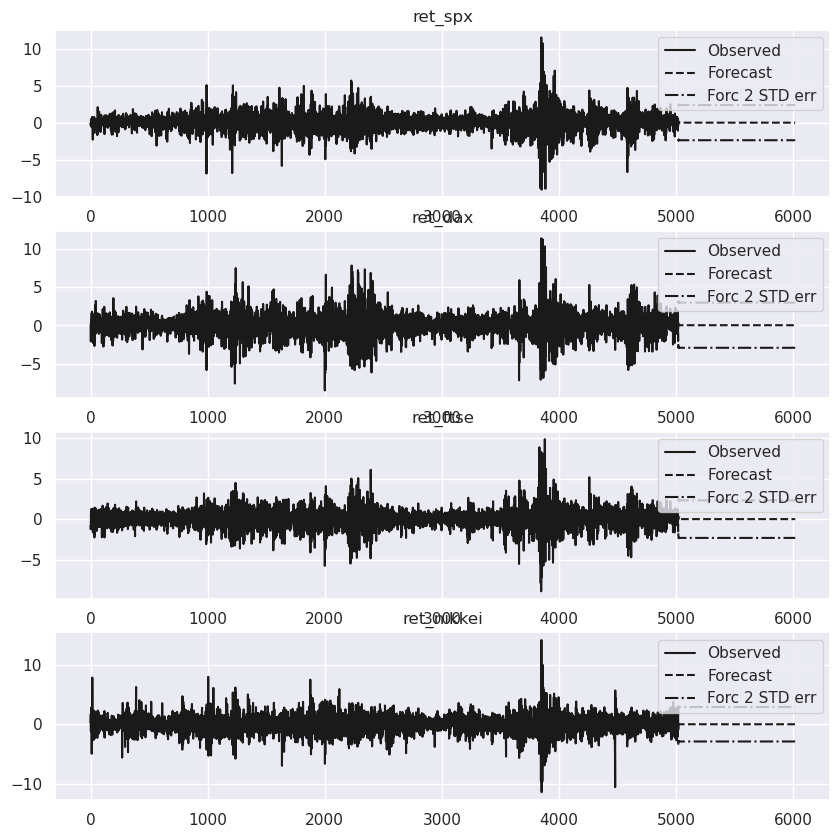

In [101]:
results_var_ret.plot_forecast(1000)
plt.show()